# Setup Notebook and DataFrame
- Import libraries for manipulation, visualization and modelling
- Import and visualize DataFrame
- Treat DataFrame

## Import Libraries

In [51]:
#path configuration
import os
import sys

#data manipulation
import pandas as pd
import numpy as np

#data visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import seaborn as sns

#import warning
import warnings
warnings.filterwarnings("ignore")

#reference seed
seed = 42
np.random.seed(seed)

## Import DataFrame

In [52]:
#dataframe with simulation indicator
df_sim = pd.read_pickle(f"data/reference_dpi.pkl").T

#dataframe with simulation results
df_res = pd.read_pickle(f"data/reference_result.pkl")

In [53]:
print(f"Dataframe df_sim shape: {df_sim.shape}")
df_sim.head(2)

Dataframe df_sim shape: (10000, 330)


,1,2,3,4,5,6,7,8,9,10,...,321,322,323,324,325,326,327,328,329,330
sim_1,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,...,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563
sim_2,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,...,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824


In [54]:
print(f"Dataframe df_sim shape: {df_sim.shape}")
df_res.head(2)

Dataframe df_sim shape: (10000, 330)


,simulation,total_duration,late_project,total_cost
0,1,303.47568,False,30511.468188
1,2,315.181692,False,31086.287206


## Initial Treatment

Join the two dataframes, based on their index

In [55]:
#adjust the columns name of df_sim
df_sim.columns = [f"period_{column}" for column in df_sim.columns]

#join both dataframes
df = pd.concat([df_sim.reset_index(drop = True),
                df_res[["total_duration", "late_project"]].reset_index(drop = True)],
                axis = 1)

#visualization
df

,period_1,period_2,period_3,period_4,period_5,period_6,period_7,period_8,period_9,period_10,...,period_323,period_324,period_325,period_326,period_327,period_328,period_329,period_330,total_duration,late_project
0,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,0.985419,...,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,0.988563,303.47568,False
1,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,0.825027,...,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,0.951824,315.181692,False
2,0.999795,0.999795,0.999795,0.999795,0.999795,0.999795,0.999795,0.999795,0.999795,0.999795,...,0.975372,0.975372,0.975372,0.975372,0.975372,0.975372,0.975372,0.975372,307.538437,False
3,0.805988,0.805988,0.805988,0.805988,0.805988,0.805988,0.805988,0.805988,0.805988,0.805988,...,0.953985,0.953985,0.953985,0.953985,0.953985,0.953985,0.953985,0.953985,314.461729,False
4,0.855887,0.855887,0.855887,0.855887,0.855887,0.855887,0.855887,0.855887,0.855887,0.855887,...,0.962465,0.962465,0.962465,0.962465,0.962465,0.962465,0.962465,0.962465,311.688009,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1.079481,1.079481,1.079481,1.079481,1.079481,1.079481,1.079481,1.079481,1.079481,1.079481,...,0.979924,0.979924,0.979924,0.979924,0.979924,0.979924,0.979924,0.979924,306.140124,False
9996,1.483596,1.483596,1.483596,1.483596,1.483596,1.483596,1.483596,1.483596,1.483596,1.483596,...,0.990094,0.990094,0.990094,0.990094,0.990094,0.990094,0.990094,0.990094,302.984831,False
9997,0.950001,0.950001,0.950001,0.950001,0.950001,0.950001,0.950001,0.950001,0.950001,0.950001,...,0.966136,0.966136,0.966136,0.966136,0.966136,0.966136,0.966136,0.966136,310.505425,False
9998,0.880999,0.880999,0.880999,0.880999,0.880999,0.880999,0.880999,0.880999,0.880999,0.880999,...,0.954773,0.954773,0.954773,0.954773,0.954773,0.954773,0.954773,0.954773,314.230876,False


# Consistency Check
- Verify data type, null values, duplicated rows and the distribution of the dependent variable

In [56]:
df.dtypes.value_counts()

float64    330
object       2
dtype: int64

In [57]:
df.isna().sum().sum()

0

In [58]:
df.duplicated().sum()

0

In [59]:
df.late_project.value_counts()

False    8780
True     1220
Name: late_project, dtype: int64

Comments
- All columns are floats, except the answer, that is as object
- There are no null values
- There are no duplicated values
- Around 12% of the projects are late, which characterizes our problem as an imbalanced classification problem

# Exploratory Data Analysis
- Verify Indicators Distribution, and how they perform according to late result
- Verify how correlated the indicators are

## Duration Cumulative Distribution

In [60]:
# fig = px.ecdf(df,
#         x = "total_duration",
#         title = "ECDF of the Total Duration",
#         labels = {"probability": "DPI Value", 
#                 "total_duration": "Total Duration"},
#         height = 600,
#         width = 1000)

# # Add markers for x=300 and x=320
# fig.add_trace(go.Scatter(x=[300], y=[0.028], 
#                          mode='markers+text', 
#                          showlegend = False,
#                          text=[f'(300, 0.028)'], 
#                          textposition='top left',
#                          marker=dict(size=12, color='red'), 
#                          textfont=dict(size=14, color = "black")))

# fig.add_trace(go.Scatter(x=[320], y=[0.878], 
#                          mode='markers+text',
#                          showlegend= False,
#                          text=[f'(320, 0.878)'], 
#                          textposition='top left',
#                          marker=dict(size=12, color='green'), 
#                          textfont=dict(size=14, color = "black")))

# #update trace
# fig.update_traces(line=dict(color='darkblue', width=2))  # ECDF line color and width

# #update layout
# fig.update_layout(
#     title={'font': {'size': 24}},
#     xaxis_title={'text': 'Total Duration', 'font': {'size': 20}},
#     yaxis_title={'text': 'Probability', 'font': {'size': 20}},
#     xaxis={'tickfont': {'size': 16}},
#     yaxis={'tickfont': {'size': 16}},
# #     plot_bgcolor='white',  # Background color of the plot area
# #     paper_bgcolor='white'  # Background color of the entire figure
# )

# fig.show()

In [105]:
fig = px.ecdf(df,
        x="total_duration",
        title="ECDF of the Total Duration",
        labels={"probability": "DPI Value", 
                "total_duration": "Total Duration"},
        height=600,
        width=1000)

# Add markers for x=300 and x=320
fig.add_trace(go.Scatter(x=[300], y=[0.028], 
                         mode='markers+text', 
                         showlegend=False,
                         text=[f'(300, 0.028)'], 
                         textposition='top left',
                         marker=dict(size=12, color='black', symbol='cross'),
                         textfont=dict(size=14, color="black")))

fig.add_trace(go.Scatter(x=[320], y=[0.878], 
                         mode='markers+text',
                         showlegend=False,
                         text=[f'(320, 0.878)'], 
                         textposition='top left',
                         marker=dict(size=12, color='black', symbol='circle'),
                         textfont=dict(size=14, color="black")))

# Update trace
fig.update_traces(line=dict(color='black', width=2))  # ECDF line color and width

# Update layout with border
fig.update_layout(
    title={'text': "ECDF of the Total Duration", 'font': {'size': 24}, 'x': 0.5},  # Centered title
    xaxis_title={'text': 'Total Duration', 'font': {'size': 20}},
    yaxis_title={'text': 'Probability', 'font': {'size': 20}},
    xaxis={'tickfont': {'size': 16}},
    yaxis={'tickfont': {'size': 16}},
    plot_bgcolor='white',  # Background color of the plot area
    paper_bgcolor='white',  # Background color of the entire figure
)

fig.update_layout(
    xaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    yaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    margin=dict(l=50, r=50, t=100, b=50),  # Margins for the plot
)

# Add border by creating an external layout shape
fig.add_shape(type="rect",
    xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color="lightgray", width=1.25),  # Border color and width
    fillcolor="rgba(0,0,0,0)"  # No fill, transparent
)

fig.show()


## Indicator Distribution vs Time
- Analysis of the distribution per time, considering its median and 90% confidence interval
  - Analysis using all data
  - Analysis separating on time and delayed projects



In [62]:
# def create_indicator_confidence_interval (df):

#   #create the dataframe with median and confidence interval of 90%
#   tmp = df\
#         .copy()\
#         .drop(columns = "total_duration")\
#         .describe(percentiles= [0.05, 0.5, 0.95])\
#         .T\
#         .reset_index()\
#         .rename({"index": "period",
#                   "50%": "median"}, axis = 1)\
#         .loc[:,["period", "5%", "median", "95%"]]

#   #adjust time and confidence interval columns
#   tmp["period"] = tmp["period"].apply(lambda x: int(x[7:]))
#   tmp["5%"] = tmp["median"] - tmp["5%"]
#   tmp["95%"] = tmp["95%"] - tmp["median"]

#   return tmp

In [63]:
def create_indicator_confidence_interval (df):

  #create the dataframe with median and confidence interval of 90%
  tmp = df\
        .copy()\
        .drop(columns = "total_duration")\
        .describe()\
        .T\
        .reset_index()\
        .rename({"index": "period",
                  "50%": "median"}, axis = 1)\
        .loc[:,["period", "min", "median", "mean", "max"]]

  #adjust time and confidence interval columns
  tmp["period"] = tmp["period"].apply(lambda x: int(x[7:]))
  tmp["min_error"] = tmp["median"] - tmp["min"]
  tmp["max_error"] = tmp["max"] - tmp["median"]

  return tmp

In [64]:
tmp = create_indicator_confidence_interval (df)
tmp

,period,min,median,mean,max,min_error,max_error
0,1,0.753576,1.000079,1.019087,1.499094,0.246503,0.499016
1,2,0.753576,1.000079,1.019087,1.499094,0.246503,0.499016
2,3,0.753576,1.000079,1.019087,1.499094,0.246503,0.499016
3,4,0.753576,1.000079,1.019087,1.499094,0.246503,0.499016
4,5,0.753576,1.000079,1.019087,1.499094,0.246503,0.499016
...,...,...,...,...,...,...,...
325,326,0.878984,0.961880,0.961494,1.030041,0.082896,0.068162
326,327,0.879107,0.961880,0.961497,1.030041,0.082773,0.068162
327,328,0.879230,0.961880,0.961500,1.030041,0.082650,0.068162
328,329,0.879352,0.961880,0.961501,1.030041,0.082528,0.068162


### All Projects

In [109]:
#plot the distribution of the whole dataframe
tmp = create_indicator_confidence_interval(df)
fig = px.scatter(tmp,
                title = "DPI Distribution per Time Period",
                x = "period",
                y = "median",
                error_y = "max_error",
                error_y_minus = "min_error",
                labels = {"median": "DPI Value", 
                           "period": "Time Period"},
                height = 600,
                width = 1000)


# Update trace for marker color and size
fig.update_traces(
    marker=dict(size=4, color='black'),  # Centered title'),  # Marker size and color
    error_y=dict(color='black')  # Error bars color
)

#update layout
fig.update_layout(
    title={'font': {'size': 24}, 'x': 0.5},
    xaxis_title={'text': 'Time Period', 'font': {'size': 20}},
    yaxis_title={'text': 'DPI Value', 'font': {'size': 20}},
    xaxis={'tickfont': {'size': 16}},
    yaxis={'tickfont': {'size': 16}},
    plot_bgcolor='white',  # Background color of the plot area
    paper_bgcolor='white'  # Background color of the entire figure
)

fig.update_layout(
    xaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    yaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    margin=dict(l=50, r=50, t=100, b=50),  # Margins for the plot
)

# Add border by creating an external layout shape
fig.add_shape(type="rect",
    xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color="lightgray", width=1.25),  # Border color and width
    fillcolor="rgba(0,0,0,0)"  # No fill, transparent
)

fig.show()


### Separation of late and on-time projects

In [66]:
#create dataframe with metrics
tmp_on_time = create_indicator_confidence_interval(df.loc[df.late_project == False])
tmp_on_time["result"] = "on time"

tmp_late = create_indicator_confidence_interval(df.loc[df.late_project == True])
tmp_late["result"] = "late"

tmp = pd.concat([tmp_on_time, tmp_late])

#plot figure
px.scatter(tmp,
           title = "DPI distribution per time, based on result",
           x = "period",
           y = "median",
           facet_row = "result",
           color = "result",
           error_y = "max_error",
        error_y_minus = "min_error",)

Comments:
- Despite at first sight both distributions seem familiar, we can observe that they differ in their range values on its peaks and valleys, and it seems that there is a time shift over their values
- We will plot both medians to compare if this assumptions are corrrect

In [90]:
#plot only the medians
fig = px.line(tmp.replace({"on time": "On-time",
                          "late": "Late"}),
            title = "DPI Median per Time Period, Based on the Project Outcome",
            x = "period",
            y = "median",
            labels = {"median": "DPI Median", 
                      "period": "Time Period",
                      "result": "Outcome"},
            height = 600,
            width = 1000,
            color_discrete_sequence=['black', 'black'],
            color = "result",
            # line_group = "result"
            )

# Update line colors and legend text size
fig.update_traces(
    line=dict(width=3),  # Line width
)

fig.for_each_trace(lambda t: t.update(line=dict(dash='dash') if t.name == 'Late' else dict(dash='solid')))

#update layout
fig.update_layout(
    title={'font': {'size': 24}, 'x': 0.5},
    xaxis_title={'text': 'Time Period', 'font': {'size': 20}},
    yaxis_title={'text': 'DPI Median', 'font': {'size': 20}},
    xaxis={'tickfont': {'size': 16}},
    yaxis={'tickfont': {'size': 16}},
    legend=dict(
        title='Outcome',
        font=dict(size=14),  # Increase the legend text size
        title_font=dict(size=16)),  # Increase the legend title size,  # Increase legend text size
    plot_bgcolor='white',  # Background color of the plot area
    paper_bgcolor='white'  # Background color of the entire figure
)

fig.update_layout(
    xaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    yaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    margin=dict(l=50, r=50, t=100, b=50),  # Margins for the plot
)

# Add border by creating an external layout shape
fig.add_shape(type="rect",
    xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color="lightgray", width=1.25),  # Border color and width
    fillcolor="rgba(0,0,0,0)"  # No fill, transparent
)

fig.show()

Comments:
- Analyzing only the median, it seems that our assumptions are right, and projects that are late may have some days of shift between their valleys and peak, comparing with on-time projects.
- At the beginning of the project, this shift is around 2 days, but as time passes by, it gets around 10 days. Also, late projects have consistently lower values than on-time projects

## Correlation
- We will verify the correlation using a time interval for a general ideia on the level of correlation between features

In [17]:
def plot_correlation(df,
                     index_initial,
                     index_final,
                     time_interval):

  # Adjust size and palette
  fig, ax = plt.subplots(figsize=(15,10))
  cmap = sns.diverging_palette(h_neg=10,h_pos=240,as_cmap=True)

  # Create the correlation matrix
  corr = df.loc[:,index_initial: index_final: time_interval].corr(method = "pearson")

  # Generate a mask for the upper triangle
  mask = np.triu(np.ones_like(corr, dtype=bool))

  # Add the mask to the heatmap
  sns.heatmap(corr, mask=mask, cmap=cmap, center=0, linewidths=1, annot=True, fmt=".2f", ax=ax)

  #Insert title
  ax.set_title("Correlation of the DPI Values", fontsize=16)
  
  plt.show()

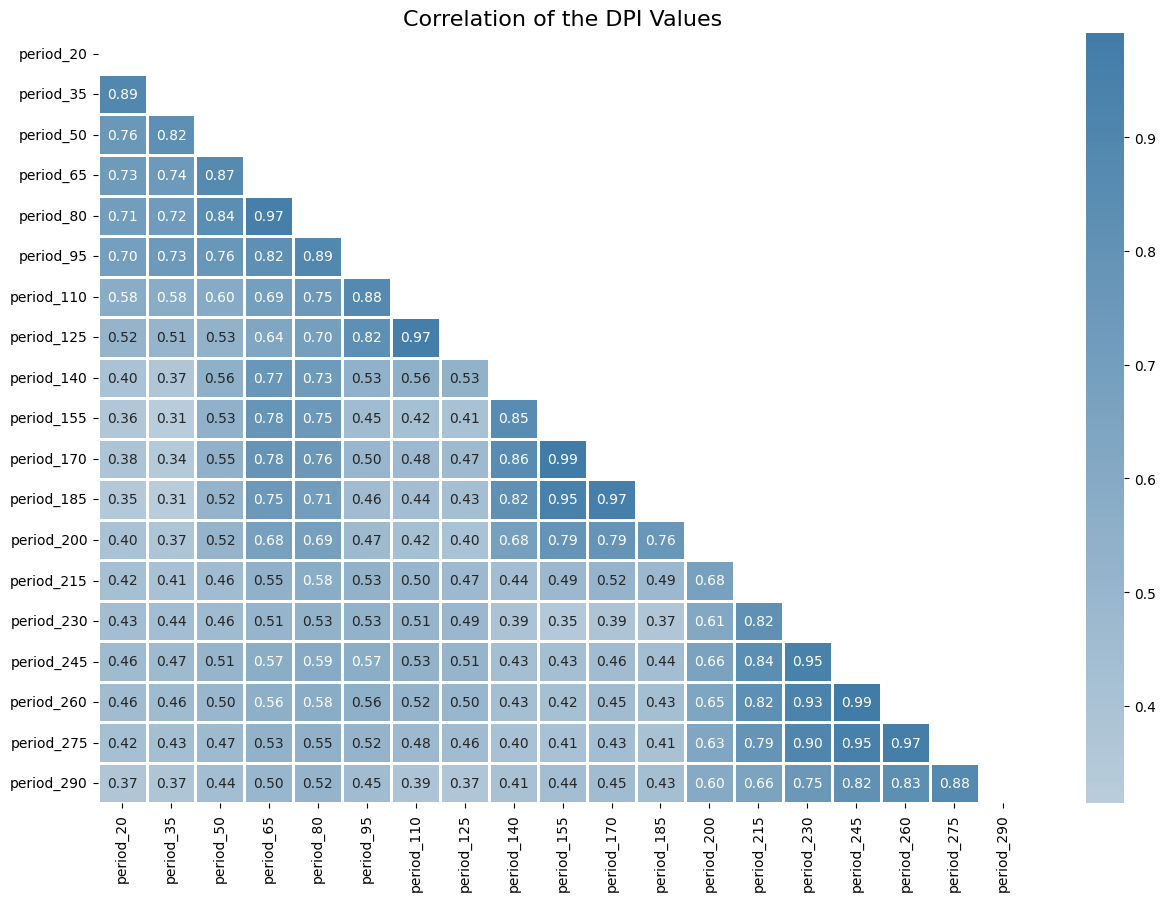

In [18]:
#function parameters
index_initial = "period_20"
index_final = "period_300"
time_interval = 15

plot_correlation(df,
                index_initial,
                index_final,
                time_interval)

Comments:
- We can observe that there are several "blocks" which the features are highly correlated. Most of them are related to the subsequent indicator (even for the time interval of 10 days), but we also have the following moments:
  - time 10 until 100 with themselves: correlations vary from 0.61 until 0.99
  - time 60 until time 80 with time 140 until 200: correlations vary from 0.69 until 0.80
  - time 150 until time 200 with themselves: correlations vary from 0.68 until 0.99
  - time 200 until time 300 with themselves: correlations vary from 0.52 until 1
- In general, having high correlated features can harm our models, so the PCA strategy can come at hand


In [19]:
#create list of lags
list_lags = [1, 5, 10, 20]

#create correlations dataframe
df_correlations = pd.DataFrame()

#create the iteration based on each lag 
for lag in list_lags:

    # Initialize an empty list to store correlation results
    correlations = []

    # Loop through the period columns and calculate correlations between adjacent periods
    for i in range(lag+1, 301):
        period_a = f'period_{i}'
        period_b = f'period_{i-lag}'
        correlation = df[period_a].corr(df[period_b])
        correlations.append({'Period': period_a, 'Lag': lag, 'Correlation': correlation})

    # Create a new dataframe from the correlations list
    df_correlation_lag = pd.DataFrame(correlations)

    #incorporate the lag correlation inside the full dataframe
    df_correlations = pd.concat([df_correlations, df_correlation_lag], axis = 0)

In [110]:
# Define the list of tick values and corresponding labels
tick_vals = [f'period_{i}' for i in range(10, 321, 10)]
tick_text = [f'Period {i}' for i in range(10, 321, 10)]  # Custom labels, optional

fig = px.line(df_correlations,
        x = "Period",
        y = "Correlation",
        color = "Lag",
        title = "Period Correlation, per Lag",
        # color_discrete_sequence=px.colors.qualitative.G10,
        color_discrete_sequence=['black', 'black', "gray", "gray"],
        width = 1000,
        height = 500)

# Update line colors and legend text size
fig.update_traces(
    line=dict(width=3),  # Line width
)

# Update layout with custom x-ticks
fig.update_layout(
    title={'font': {'size': 24}, 'x': 0.5},
    xaxis_title={'text': 'Time Period', 'font': {'size': 20}},
    yaxis_title={'text': 'Correlation', 'font': {'size': 20}},
    xaxis=dict(
        tickfont={'size': 16},
        tickvals=tick_vals,  # Set the tick positions
        ticktext=tick_text,  # Optional: set custom labels
    ),
    yaxis={'tickfont': {'size': 16}},
    legend=dict(
        title='Lag',
        font=dict(size=14),  # Increase the legend text size
        title_font=dict(size=16))  # Increase the legend title size
)

fig.update_layout(
    xaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    yaxis=dict(showgrid=True, gridcolor='lightgray'),  # Light gray gridlines
    margin=dict(l=50, r=50, t=100, b=50),  # Margins for the plot
        plot_bgcolor='white',  # Background color of the plot area
    paper_bgcolor='white'  # Background color of the entire figure
)

# Add border by creating an external layout shape
fig.add_shape(type="rect",
    xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color="lightgray", width=1.25),  # Border color and width
    fillcolor="rgba(0,0,0,0)"  # No fill, transparent
)

# Update line styles
dashes = ['solid', 'dashdot', 'solid', 'dashdot']  # Different dash styles

# Apply different dash styles to each trace
for i, dash_style in enumerate(dashes):
    fig.data[i].update(line=dict(dash=dash_style, width=3))  # Assign dash styles

fig.show()


'solid': No dashes (continuous line)
'dash': Short dashes
'dot': Dots
'dashdot': Dash-dot pattern
'longdash': Long dashes
'longdashdot': Long dash followed by a dot

# Gantt Chart

In [159]:
#read csv
df_gc = pd.read_csv("data/gantt_chart.csv", delimiter = ";", index_col="index")

df_gc.replace({"NaT": np.nan}, inplace = True)

#convert columns
df_gc['baseline_start'] = pd.to_timedelta(df_gc['baseline_start'].str.replace('days', '').astype(float), unit='d')
df_gc['baseline_end'] = pd.to_timedelta(df_gc['baseline_end'].str.replace('days', '').astype(float), unit='d')
df_gc['initial_project_date'] = pd.to_datetime(df_gc['initial_project_date'], errors='coerce', format="%d/%m/%Y")
df_gc['start_date'] = pd.to_datetime(df_gc['start_date'], errors='coerce', format="%d/%m/%y")
df_gc['end_date'] = pd.to_datetime(df_gc['end_date'], errors='coerce', format="%d/%m/%y")
df_gc['critical_path'] = df_gc['critical_path'].apply(lambda x: "True" if x == "TRUE" else ("False" if x == "FALSE" else "Buffer"))
df_gc

,activity,baseline_start,baseline_end,initial_project_date,start_date,end_date,critical_path
index,,,,,,,
0,2,0 days,15 days,NaT,2022-01-01,2022-01-16,True
1,3,15 days,45 days,NaT,2022-01-16,2022-02-15,True
2,4,15 days,45 days,NaT,2022-01-16,2022-02-15,True
3,5,45 days,100 days,NaT,2022-02-15,2022-04-11,True
4,6,45 days,115 days,NaT,2022-02-15,2022-04-26,True
5,7,45 days,135 days,NaT,2022-02-15,2022-05-16,True
6,8,15 days,85 days,NaT,2022-01-16,2022-03-27,True
7,10,115 days,140 days,NaT,2022-04-26,2022-05-21,True
8,11,115 days,200 days,NaT,2022-04-26,2022-07-20,False


In [166]:
import plotly.express as px

# Create the Gantt chart
fig = px.timeline(df_gc, 
                  x_start="start_date", x_end="end_date", 
                  y="activity", 
                  category_orders={"activity": df_gc.activity.unique()}, 
                  color="critical_path",  # Color by critical path
                  labels={"critical_path": "Critical Path"},
                  width=1000, height=600,
                  template="seaborn",
                  color_discrete_sequence=["black", "dimgray", "gray"]
                 )

# Update x-axis properties
fig.update_xaxes(
    title_text="Month", 
    nticks=15, 
    showgrid=True, 
    tickformat='%m',
    title_font=dict(size=20),
    tickfont=dict(size=14),
    gridcolor="lightgray"  # Light gray grid
)

# Update y-axis properties
fig.update_yaxes(
    title_text="Activity",
    nticks=50, 
    autorange="reversed",
    showgrid=True,
    title_font=dict(size=20),
    tickfont=dict(size=14),
    gridcolor="lightgray"  # Light gray grid
)

# Update layout for title, legend, and background colors
fig.update_layout(
    title_text="Project Gantt Chart",
    title_x=0.5,
    title_font=dict(size=24),
    plot_bgcolor="white",  # White background for plot area
    paper_bgcolor="white",  # White background for the entire figure
    legend=dict(
        title=dict(font=dict(size=18)),  # Legend title font size
        font=dict(size=16),  # Legend item font size
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=0.89
    )
)

# Display the figure
fig.show()


# Export DataFrame

In [ ]:
df.drop(columns = "total_duration").to_csv("df_dpi.csv", index_label= False)